In [1]:
import numpy as np
import matplotlib.pyplot as plt
import umap

from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

/home/users/urikokp2/.conda/envs/2026ALMOND2/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
u = np.load("../data/cortex_u.npy", allow_pickle=True).ravel()

label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(u)

embedding = np.load("../save/cortex/IWRCL/M100/seed42/generated.npy")

pred = KMeans(
    n_clusters=len(label_encoder.classes_),
    random_state=0,
    n_init=10,
).fit_predict(embedding)

ari = metrics.adjusted_rand_score(labels, pred)
nmi = metrics.normalized_mutual_info_score(labels, pred)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.7808
NMI: 0.7288


/home/users/urikokp2/.conda/envs/2026ALMOND2/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


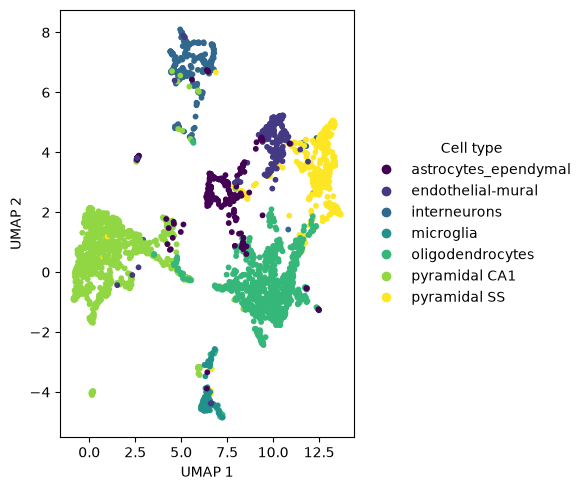

In [5]:
embedding_2 = umap.UMAP(
    random_state=42,
).fit_transform(embedding)

plt.figure(figsize=(6, 5))

scatter = plt.scatter(
    embedding_2[:, 0],
    embedding_2[:, 1],
    c=labels,
    s=10,
)

handles, _ = scatter.legend_elements()

plt.legend(
    handles,
    label_encoder.classes_,
    title="Cell type",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False,
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.tight_layout()
plt.show()